# Eje 7a — Monte Carlo paso a paso

Derivados Financieros · QUANt UCEMA · **Pricing avanzado**

Simulamos el subyacente bajo la medida riesgo-neutral y promediamos payoffs descontados.
Es el método más flexible: sirve para path-dependent y payoffs raros.

| Hermano | Contenido |
|---------|-----------|
| **07a** | Monte Carlo |
| 07b | Diferencias finitas |
| 07c | QuantLib |
| 07d | Comparación de modelos |

**Plan**
1. Idea GBM riesgo-neutral
2. Parámetros y caminos de ejemplo
3. MC a mano → media descontada
4. `Codigo.pricing.opcion_europea_mc` / antithetic
5. Convergencia vs Black–Scholes
6. Resumen

## 1) Setup

In [1]:
import math
import sys
import timeit
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
for p in [ROOT, *ROOT.parents]:
    if (p / "Codigo" / "pricing").exists():
        sys.path.insert(0, str(p))
        break

print("OK")

OK


In [2]:
from Codigo.pricing import (
    opcion_europea_bs,
    opcion_europea_mc,
    opcion_europea_mc_fv,
)

## 2) Idea

Bajo la medida riesgo-neutral:

$$
S_T = S_0 \exp\Big((r-q-\tfrac12\sigma^2)T + \sigma\sqrt{T}\,Z\Big),\quad Z\sim N(0,1)
$$

Para una call europea:

$$
V_0 \approx e^{-rT}\frac{1}{N}\sum_{i=1}^{N}\max(S_T^{(i)}-K,0)
$$

El error típico baja como $1/\sqrt{N}$.

## 3) Parámetros

In [3]:
tipo = "C"
S, K, T = 100.0, 100.0, 1.0
r, sigma, div = 0.05, 0.25, 0.0
n_paths = 50_000
np.random.seed(42)
print(f"{tipo=}  {S=}  {K=}  {T=}  {r=}  {sigma=}  {div=}  {n_paths=}")

tipo='C'  S=100.0  K=100.0  T=1.0  r=0.05  sigma=0.25  div=0.0  n_paths=50000


## 4) Caminos GBM (visual)

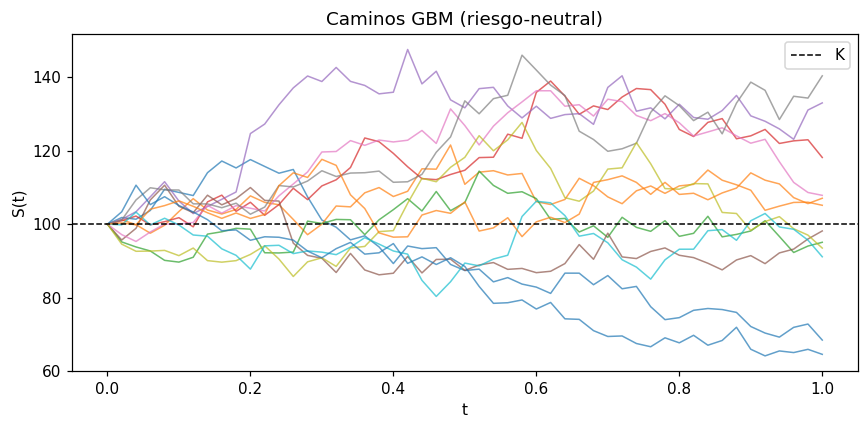

In [4]:
n_show, n_steps = 12, 50
dt = T / n_steps
t = np.linspace(0, T, n_steps + 1)
fig, ax = plt.subplots(figsize=(8, 4), dpi=110)
for _ in range(n_show):
    z = np.random.normal(size=n_steps)
    log_incs = (r - div - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * z
    path = S * np.exp(np.concatenate([[0.0], np.cumsum(log_incs)]))
    ax.plot(t, path, alpha=0.7, lw=1)
ax.axhline(K, color="k", ls="--", lw=1, label="K")
ax.set_title("Caminos GBM (riesgo-neutral)")
ax.set_xlabel("t"); ax.set_ylabel("S(t)")
ax.legend(); plt.tight_layout(); plt.show()

## 5) Monte Carlo a mano

In [5]:
z = np.random.normal(0, 1, n_paths)
ST = S * np.exp((r - div - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * z)
payoff = np.maximum(ST - K, 0.0) if tipo == "C" else np.maximum(K - ST, 0.0)
disc = np.exp(-r * T)
pay_disc = disc * payoff
v_manual = float(np.mean(pay_disc))
stderr = float(np.std(pay_disc, ddof=1) / np.sqrt(n_paths))
print(f"V_MC manual = {v_manual:.6f}  ± {1.96*stderr:.6f} (IC ~95%)")

V_MC manual = 12.331824  ± 0.161779 (IC ~95%)


## 6) Verificación con `Codigo` + antithetic

In [6]:
v_lib = opcion_europea_mc(tipo, S, K, T, r, sigma, div, n_paths)
v_fv = opcion_europea_mc_fv(tipo, S, K, T, r, sigma, div, n_paths)
v_bs = opcion_europea_bs(tipo, S, K, T, r, sigma, div)
print(f"MC lib       = {v_lib:.6f}")
print(f"MC antithetic= {v_fv:.6f}")
print(f"Black–Scholes= {v_bs:.6f}")
print(f"|MC−BS|={abs(v_lib-v_bs):.6f}  |MCfv−BS|={abs(v_fv-v_bs):.6f}")

MC lib       = 12.403793
MC antithetic= 12.326263
Black–Scholes= 12.335999
|MC−BS|=0.067794  |MCfv−BS|=0.009736


## 7) Convergencia vs N

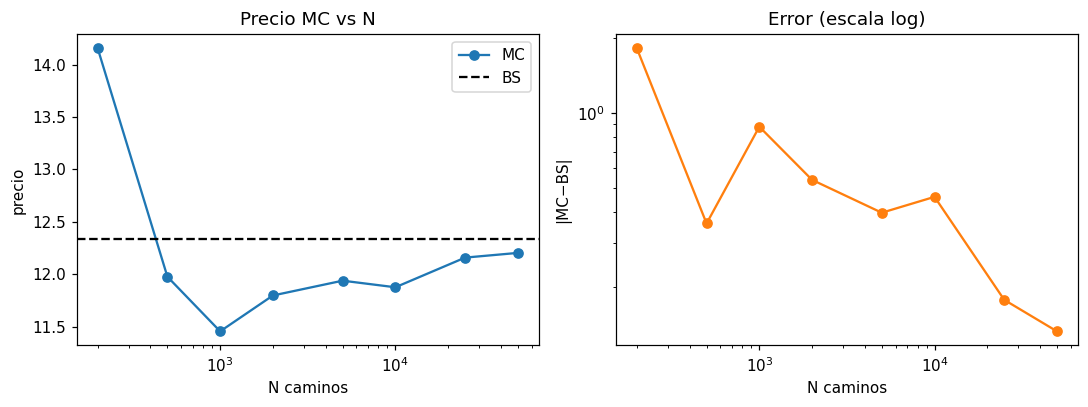

In [7]:
Ns = [200, 500, 1000, 2000, 5000, 10000, 25000, 50000]
errs, prices = [], []
for n in Ns:
    np.random.seed(0)
    p = opcion_europea_mc(tipo, S, K, T, r, sigma, div, n)
    prices.append(p)
    errs.append(abs(p - v_bs))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), dpi=110)
ax[0].plot(Ns, prices, "o-", label="MC")
ax[0].axhline(v_bs, color="k", ls="--", label="BS")
ax[0].set_xscale("log"); ax[0].set_xlabel("N caminos"); ax[0].set_ylabel("precio")
ax[0].legend(); ax[0].set_title("Precio MC vs N")
ax[1].plot(Ns, errs, "o-", color="C1")
ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_xlabel("N caminos"); ax[1].set_ylabel("|MC−BS|")
ax[1].set_title("Error (escala log)")
plt.tight_layout(); plt.show()

## Resumen

- MC = promedio de payoffs descontados bajo GBM riesgo-neutral.
- Error ≈ $O(1/\sqrt{N})$; antithetic (`opcion_europea_mc_fv`) suele acercarse más rápido.
- Ideal para payoffs path-dependent / exóticos; para vanilla europea BS es exacto y más rápido.

**Ejercicio:** repetí con put ATM y compará IC 95% de MC vs MC antithetic (mismo `n_paths`).

**Siguiente:** **07b** — diferencias finitas paso a paso.